# Kingdom Open (DGVTour #9): a first look at hole-by-hole data

This notebook analyzes one Disc Golf Vermont Tour event, PDGA event 98424, and reproduces
every number the project proposal quotes from it. It also builds the proposal's
preliminary figure.

**To run it:** run all cells. The data is read from the parsed 2026 tables in
`data/2026/processed/` (built by `dgvt_styles/scrape.py`). Ratings are each player's
PDGA rating at the time of the event (`event_rating`), not their current rating.

| Section | What it shows | Used in the proposal |
|---|---|---|
| 1 | Event overview | "Example event" paragraph |
| 2 | Data quality checks | Cleaning risks (999 scores, hole lengths) |
| 3 | Layouts, divisions, tee times | Cleaning risks (tees, small divisions, start format) |
| 4 | Hole types | Hole type variable |
| 5 | Score mix | Predictive target |
| 6 | Same score, different path | Figure 1 (the two circled players) |
| 7 | Strokes gained | Key derived variable |
| 8 | Preliminary figure | Figure 1 |
| 9 | Short holes versus long holes | First look at playing style |
| 10 | Every proposal number in one table | All of the above |

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EVENT_ID = 98424
# Find the repo root whether the notebook is run from notebooks/ or the repo itself.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgvt_styles").is_dir())
sys.path.insert(0, str(ROOT))
from dgvt_styles.features import add_training_flag, add_strokes_gained
DATA_DIR = ROOT / "data" / "2026" / "processed"

events = pd.read_csv(DATA_DIR / "events.csv")
# in_training: has a PDGA number and an event-time rating. Players without one still count toward
# strokes gained but are left out of anything fit on players (same rule as dgvt-eda.ipynb).
rounds_all = add_training_flag(pd.read_csv(DATA_DIR / "rounds.csv"))
hole_scores_all = add_training_flag(pd.read_csv(DATA_DIR / "hole_scores.csv"))
holes_all = pd.read_csv(DATA_DIR / "holes.csv")

info = events.set_index("event_id").loc[EVENT_ID]

# One row per player per round. `rating` is the PDGA rating at the time of the event.
players_raw = (rounds_all[rounds_all["event_id"] == EVENT_ID]
               .rename(columns={"event_rating": "rating", "layout_name": "layout",
                                "raw_completed": "completed"})
               .reset_index(drop=True))
layout_names = players_raw.drop_duplicates("layout_id").set_index("layout_id")["layout"]

# One row per player per round per hole, with the layout name attached.
hole_scores = (hole_scores_all[hole_scores_all["event_id"] == EVENT_ID]
               .rename(columns={"event_rating": "rating"})
               .assign(layout=lambda d: d["layout_id"].map(layout_names))
               .reset_index(drop=True))

# One row per layout per hole. Layouts nobody played (PDGA's placeholder "Default Layout")
# are dropped.
course = (holes_all[(holes_all["event_id"] == EVENT_ID)
                    & holes_all["layout_id"].isin(layout_names.index)]
          .assign(layout=lambda d: d["layout_id"].map(layout_names))
          .reset_index(drop=True))

FIG_DIR = ROOT / "Documents" / "figures"        # the proposal includes figures/ from here
FIG_DIR.mkdir(exist_ok=True)

print(f"rounds file:      {players_raw.shape[0]:>5} rows (one per player per round)")
print(f"hole scores file: {hole_scores.shape[0]:>5} rows (one per player per round per hole)")
print(f"holes file:       {course.shape[0]:>5} rows (one per layout per hole)")

rounds file:        208 rows (one per player per round)
hole scores file:  3708 rows (one per player per round per hole)
holes file:          72 rows (one per layout per hole)


In [2]:
# Shared chart styling: quiet axes and grid, colors chosen to stay distinguishable
# for readers with color vision deficiency.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
BAND_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # one hue, light to dark

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def titled(ax, title, subtitle=None, size=None):
    # Left-aligned title with an optional one-line subtitle underneath.
    ax.set_title(title, pad=22 if subtitle else 8, fontsize=size)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, va="bottom",
                fontsize=(size or plt.rcParams["axes.titlesize"]) - 3, color=INK_2)

## 1. Event overview

In [3]:
n_players = players_raw["player_key"].nunique()
n_divisions = players_raw["division"].nunique()
n_rounds = players_raw["round"].nunique()
n_player_holes = len(hole_scores)
n_unrated = players_raw.loc[players_raw["rating"].isna(), "player_key"].nunique()
n_rounds_no_pdga = int((~players_raw["has_pdga_number"]).sum())
n_rounds_unrated = int((players_raw["has_pdga_number"] & ~players_raw["in_training"]).sum())

overview = pd.DataFrame({"value": {
    "Event": info["name"],
    "Dates": f"{info['start_date']} to {info['end_date']}",
    "Location": info["location"],
    "Tier": f"{info['tier']}-Tier",
    "Course": ", ".join(course["course_name"].unique()),
    "Players": n_players,
    "Players unrated at the time": n_unrated,
    "Divisions with players": n_divisions,
    "Rounds": n_rounds,
    "Player-round rows": len(players_raw),
    "Player-hole scores": n_player_holes,
    "Player-rounds with no PDGA number (field only, not training)": n_rounds_no_pdga,
    "Player-rounds unrated at the time (field only, not training)": n_rounds_unrated,
}})
overview

,value
Event,DGVTour #9 - Kingdom Open
Dates,2026-08-22 to 2026-08-23
Location,"Lyndonville, Vermont"
Tier,B-Tier
Course,The Wildflower DGC
Players,104
Players unrated at the time,7
Divisions with players,17
Rounds,2
Player-round rows,208


## 2. Data quality checks

Three things to settle before any analysis: unfinished rounds, whether hole scores agree
with the official round totals, and where the hole lengths live.

### 2a. Unfinished rounds are stored by PDGA as a score of 999

The parser blanks those scores and flags the round in `unfinished_999`.

In [4]:
dnf = players_raw[players_raw["unfinished_999"]]
print(f"{len(dnf)} player-rounds were scored 999 by PDGA; "
      f"{int(dnf['completed'].sum())} of them are still flagged completed=True")
display(dnf[["division", "round", "rating", "round_score", "round_rating", "completed"]])

# Keep only real rounds from here on.
players = players_raw[~players_raw["unfinished_999"]].copy()
n_completed = len(players)
print(f"{n_completed} completed player-rounds remain")

2 player-rounds were scored 999 by PDGA; 2 of them are still flagged completed=True


,division,round,rating,round_score,round_rating,completed
81,MA2,2,NaN,NaN,NaN,True
207,MPO,2,948.0,NaN,NaN,True


206 completed player-rounds remain


### 2b. Hole scores sum to the official round score

In [5]:
hole_totals = (hole_scores.groupby(["player_key", "round"], as_index=False)
               .agg(hole_sum=("score", "sum"), holes=("hole", "count")))
check = players.merge(hole_totals, on=["player_key", "round"], how="left")

n_with_holes = int(check["holes"].notna().sum())
n_sum_ok = int((check["hole_sum"] == check["round_score"]).sum())
print(f"{n_with_holes} of {n_completed} completed player-rounds have hole scores")
print(f"{n_sum_ok} of {n_completed}: the hole scores sum to the official round score")
print("Holes recorded per player-round:", check["holes"].astype(int).value_counts().to_dict())
print("Missing individual hole scores:", int(hole_scores["score"].isna().sum()))

206 of 206 completed player-rounds have hole scores
206 of 206: the hole scores sum to the official round score
Holes recorded per player-round: {18: 206}
Missing individual hole scores: 0


### 2c. Hole lengths come from the player's layout

PDGA leaves hole lengths blank in the score data. The scraper joins each score to its
layout's hole table, so here we only check that every score has a length that matches the
holes file.

In [6]:
n_len_missing = int(hole_scores["length_ft"].isna().sum())
print(f"length_ft is missing in {n_len_missing} of {len(hole_scores)} hole-score rows")

layout_holes = course[["layout_id", "hole", "par", "length_ft"]]
holes = hole_scores.merge(layout_holes, on=["layout_id", "hole"], how="left",
                          suffixes=("", "_layout"), validate="many_to_one")
n_mismatch = int(((holes["length_ft"] != holes["length_ft_layout"])
                  | (holes["par"] != holes["par_layout"])).sum())
print(f"{n_mismatch} rows disagree with the holes file on par or length")
holes = holes.drop(columns=["par_layout", "length_ft_layout"])

length_ft is missing in 0 of 3708 hole-score rows
0 rows disagree with the holes file on par or length


## 3. Layouts, divisions, and tee times

Divisions play different tees on the same course, so a "field average" only makes sense
among players on the same layout.

In [7]:
layout_def = course.rename(columns={"hole": "label"})           # one row per layout and hole
layouts = layout_def.groupby("layout").agg(
    holes=("label", "count"), par=("par", "sum"), length_ft=("length_ft", "sum"))
layouts["players"] = players.groupby("layout")["player_key"].nunique()
layouts["divisions"] = (players.groupby("layout")["division"]
                        .agg(lambda s: ", ".join(sorted(s.unique()))))
layouts = layouts.sort_values("length_ft", ascending=False)
layouts

,holes,par,length_ft,players,divisions
layout,,,,,
Gold tees,18,64,8001.0,24,"MP40, MPO"
Blue tees,18,65,7054.0,56,"MA1, MA2, MA40, MA50, MP50, MP60"
White tees,18,63,5153.0,19,"FA40, FP40, FPO, MA3, MA60, MA70"
Red tees,18,63,4034.0,5,"FJ08, FJ10, FJ12"


In [8]:
div_sizes = (players.groupby("division")["player_key"].nunique()
             .sort_values(ascending=False).rename("players"))
n_small_divs = int((div_sizes <= 3).sum())
print(f"{n_small_divs} of {len(div_sizes)} divisions have three or fewer players")
div_sizes.to_frame().T

10 of 17 divisions have three or fewer players


division,MPO,MA1,MA2,MP50,MA40,MA3,MP40,FP40,MA60,FPO,FJ12,MA50,MA70,FJ10,FJ08,MP60,FA40
players,17,15,15,13,10,8,7,3,3,2,2,2,2,2,1,1,1


The event used tee times, not a shotgun start. Divisions on the same layout teed off
hours apart, so they did not play in identical conditions.

In [9]:
tee = (players.groupby(["round", "layout", "division"])["tee_time"]
       .agg(first_tee="min", last_tee="max").reset_index())
first_tee, last_tee = players["tee_time"].dropna().min(), players["tee_time"].dropna().max()
print(f"Tee times ran from {first_tee[:5]} to {last_tee[:5]}")
tee[tee["round"] == 1].sort_values("first_tee").reset_index(drop=True)

Tee times ran from 08:00 to 14:00


,round,layout,division,first_tee,last_tee
0,1,Red tees,FJ12,08:00:00,08:00:00
1,1,Red tees,FJ08,08:10:00,08:10:00
2,1,Red tees,FJ10,08:10:00,08:10:00
3,1,White tees,MA3,08:40:00,09:00:00
4,1,White tees,MA70,08:50:00,08:50:00
5,1,White tees,MA60,09:10:00,09:10:00
6,1,White tees,FA40,09:20:00,09:20:00
7,1,White tees,FPO,09:20:00,09:20:00
8,1,White tees,FP40,09:30:00,09:30:00
9,1,Blue tees,MA2,09:50:00,10:20:00


## 4. Hole types

Par alone is a coarse label: hole length varies a lot within a par, which is why the
proposal splits holes by length within par.

In [10]:
length_by_par = (layout_def.groupby(["layout", "par"])["length_ft"]
                 .agg(holes="count", shortest_ft="min", longest_ft="max").reset_index())
length_by_par["layout"] = pd.Categorical(length_by_par["layout"], categories=layouts.index, ordered=True)
length_by_par.sort_values(["layout", "par"]).reset_index(drop=True)

,layout,par,holes,shortest_ft,longest_ft
0,Gold tees,3,9,240.0,492.0
1,Gold tees,4,8,414.0,631.0
2,Gold tees,5,1,775.0,775.0
3,Blue tees,3,8,221.0,335.0
4,Blue tees,4,9,379.0,543.0
5,Blue tees,5,1,776.0,776.0
6,White tees,3,10,191.0,306.0
7,White tees,4,7,293.0,391.0
8,White tees,5,1,605.0,605.0
9,Red tees,3,10,119.0,189.0


How hard each hole played, against its length, on the layout with the biggest field.
Length matters, but it is far from the whole story: two par 4s of nearly the same length
can differ by more than half a stroke. So a hole's type should use how it played for the
field as well as its length.

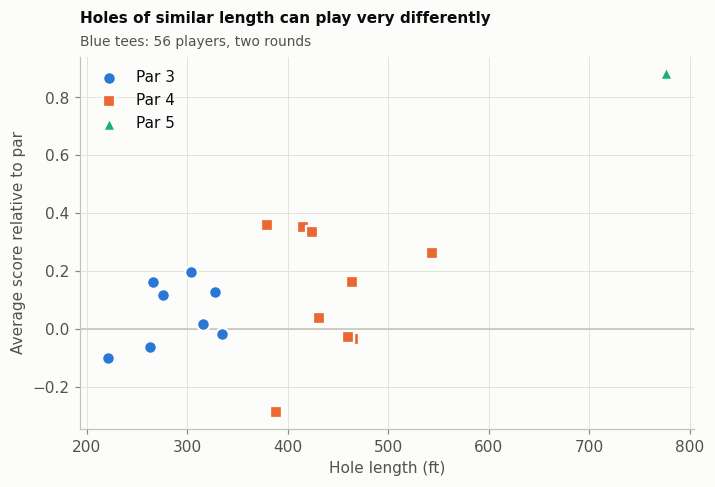

Par 3s: correlation between length and average score to par = 0.36 (8 holes)
Par 4s: correlation between length and average score to par = 0.08 (9 holes)
Holes 11 and 5 (both par 4) are 9 ft apart in length but played 0.65 strokes apart on average


hole,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
par,4.00,4.00,4.00,3.0,4.00,3.00,4.00,3.00,4.00,3.0,4.00,3.00,4.00,3.00,3.00,3.00,5.00,4.00
length_ft,543.00,465.00,415.00,221.0,388.00,266.00,431.00,263.00,464.00,304.0,379.00,335.00,460.00,328.00,316.00,276.00,776.00,424.00
avg_to_par,0.26,-0.04,0.35,-0.1,-0.29,0.16,0.04,-0.06,0.16,0.2,0.36,-0.02,-0.03,0.13,0.02,0.12,0.88,0.33


In [11]:
LAYOUT = layouts["players"].idxmax()      # the layout with the most players
lay = holes[holes["layout"] == LAYOUT]

hole_stats = (lay.groupby("hole")
              .agg(par=("par", "first"), length_ft=("length_ft", "first"),
                   avg_to_par=("score_to_par", "mean"))
              .reset_index())

fig, ax = plt.subplots(figsize=(7.2, 4.4))
par_style = {3: (BLUE, "o"), 4: (ORANGE, "s"), 5: (AQUA, "^")}
for par, (color, marker) in par_style.items():
    d = hole_stats[hole_stats["par"] == par]
    ax.scatter(d["length_ft"], d["avg_to_par"], s=70, color=color, marker=marker,
               edgecolor=SURFACE, linewidth=1.5, label=f"Par {par}", zorder=3)
ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
ax.set_xlabel("Hole length (ft)")
ax.set_ylabel("Average score relative to par")
titled(ax, "Holes of similar length can play very differently",
       f"{LAYOUT}: {lay['player_key'].nunique()} players, two rounds")
ax.legend(loc="upper left", title=None)
plt.show()

for par in (3, 4):
    d = hole_stats[hole_stats["par"] == par]
    print(f"Par {par}s: correlation between length and average score to par = "
          f"{d['length_ft'].corr(d['avg_to_par']):.2f} ({len(d)} holes)")

# Par 4s of nearly the same length (within 10 ft): how far apart did they play?
p4 = hole_stats[hole_stats["par"] == 4].sort_values("length_ft").reset_index(drop=True)
near = p4.assign(next_hole=p4["hole"].shift(-1), next_len=p4["length_ft"].shift(-1),
                 next_score=p4["avg_to_par"].shift(-1)).dropna()
near["length_gap"] = near["next_len"] - near["length_ft"]
near["score_gap"] = (near["next_score"] - near["avg_to_par"]).abs()
closest = near[near["length_gap"] <= 10].sort_values("score_gap", ascending=False).iloc[0]
print(f"Holes {int(closest['hole'])} and {int(closest['next_hole'])} (both par 4) are "
      f"{int(closest['length_gap'])} ft apart in length but played "
      f"{closest['score_gap']:.2f} strokes apart on average")

hole_stats.set_index("hole").round(2).T

## 5. Score mix

The proposal's predictive task is the score category on each hole. All four categories
are well populated.

In [12]:
CATS = ["Birdie or better", "Par", "Bogey", "Double bogey or worse"]
holes["category"] = pd.cut(holes["score_to_par"], bins=[-np.inf, -1, 0, 1, np.inf], labels=CATS)

mix = holes["category"].value_counts().reindex(CATS)
mix_table = pd.DataFrame({"hole scores": mix, "share (%)": (100 * mix / mix.sum()).round(1)})
display(mix_table)

mix_by_layout = (100 * pd.crosstab(holes["layout"], holes["category"], normalize="index")).round(1)
mix_by_layout.reindex(layouts.index)

,hole scores,share (%)
category,,
Birdie or better,763,20.6
Par,1878,50.6
Bogey,765,20.6
Double bogey or worse,302,8.1


category,Birdie or better,Par,Bogey,Double bogey or worse
layout,,,,
Gold tees,24.1,52.4,18.2,5.3
Blue tees,21.6,51.6,20.1,6.7
White tees,16.4,51.9,23.4,8.3
Red tees,8.3,27.2,27.8,36.7


## 6. Same score, different path

A real case of the proposal's motivating example: two players with the same rating and
the same total who got there differently. This searches for pairs on the same layout, with the same
36-hole total, rated within 5 points of each other, and ranks them by how different
their birdie counts are.

In [13]:
player_summary = (holes.groupby(["player_key", "division", "layout"])
                  .agg(rating=("rating", "first"),
                       holes=("score", "count"),
                       to_par=("score_to_par", "sum"),
                       birdies=("score_to_par", lambda s: int((s < 0).sum())),
                       pars=("score_to_par", lambda s: int((s == 0).sum())),
                       bogeys=("score_to_par", lambda s: int((s == 1).sum())),
                       doubles_plus=("score_to_par", lambda s: int((s >= 2).sum())))
                  .reset_index())
player_summary["over_par_holes"] = player_summary["bogeys"] + player_summary["doubles_plus"]

full = player_summary[player_summary["holes"] == 36]           # both rounds completed
pairs = full.merge(full, on=["layout", "to_par"], suffixes=("_a", "_b"))
pairs = pairs[(pairs["player_key_a"] < pairs["player_key_b"])
              & ((pairs["rating_a"] - pairs["rating_b"]).abs() <= 5)]
pairs["birdie_gap"] = (pairs["birdies_a"] - pairs["birdies_b"]).abs()
pairs = pairs.sort_values("birdie_gap", ascending=False)

cols = ["layout", "to_par", "division_a", "rating_a", "birdies_a", "over_par_holes_a",
        "division_b", "rating_b", "birdies_b", "over_par_holes_b", "birdie_gap"]
pairs[cols].head(8).reset_index(drop=True)

,layout,to_par,division_a,rating_a,birdies_a,over_par_holes_a,division_b,rating_b,birdies_b,over_par_holes_b,birdie_gap
0,Blue tees,-4,MP50,942.0,14,8,MP50,938.0,10,5,4
1,Blue tees,9,MP50,905.0,4,10,MP50,905.0,6,14,2
2,Blue tees,9,MP50,905.0,6,14,MP50,900.0,4,8,2
3,Gold tees,1,MPO,978.0,9,9,MPO,975.0,11,11,2
4,Gold tees,-6,MPO,968.0,13,5,MPO,970.0,12,5,1
5,Blue tees,9,MP50,905.0,4,10,MA1,901.0,5,9,1
6,Blue tees,9,MP50,905.0,6,14,MA1,901.0,5,9,1
7,Blue tees,9,MA40,884.0,5,10,MP50,879.0,6,12,1


In [14]:
# The pair quoted in the proposal: the largest birdie gap among same-rating, same-score pairs.
example = pairs.iloc[0]
example_ids = [example["player_key_a"], example["player_key_b"]]
names = players.drop_duplicates("player_key").set_index("player_key")
example_rows = (player_summary[player_summary["player_key"].isin(example_ids)]
                .assign(name=lambda d: d["player_key"].map(names["player_name"]),
                        current_rating=lambda d: d["player_key"].map(names["current_rating"]))
                .sort_values("birdies")
                [["name", "division", "layout", "rating", "current_rating", "to_par", "birdies",
                  "pars", "bogeys", "doubles_plus", "over_par_holes"]])
# Check the ratings against the rounds table: each player has one event rating.
for pk, rating in zip(example_rows.index.map(player_summary["player_key"]), example_rows["rating"]):
    assert set(players.loc[players["player_key"] == pk, "rating"]) == {rating}
example_rows.reset_index(drop=True)

,name,division,layout,rating,current_rating,to_par,birdies,pars,bogeys,doubles_plus,over_par_holes
0,Todd Holmes,MP50,Blue tees,938.0,940.0,-4,10,21,4,1,5
1,Chris Young,MP50,Blue tees,942.0,937.0,-4,14,14,6,2,8


## 7. Strokes gained

Strokes gained on a hole is the field's average score on that hole, in that round and on
that layout, minus the player's score. Positive means better than the field. Computing
it within a layout and round removes hole difficulty and the day's conditions.

Every player is part of the field, including those with no rating, but only rated players
(`in_training`) are used when comparing strokes gained with rating.

In [15]:
# Shared helper: the field is everyone on the same layout, round and hole, rated or not.
holes = add_strokes_gained(holes)

# By construction it averages to zero on every hole.
assert holes.groupby(["layout", "round", "hole"])["strokes_gained"].mean().abs().max() < 1e-9

player_sg = (holes.groupby(["player_key", "layout"])
             .agg(rating=("rating", "first"), holes=("score", "count"),
                  sg_per_hole=("strokes_gained", "mean"), in_training=("in_training", "all"))
             .reset_index())
player_sg = player_sg[player_sg["in_training"]]       # rated players only from here

# How much of this is just skill? Rating against strokes gained, by layout.
# Layouts with fewer than 10 players are left out: a correlation over 3 players means nothing.
big_layouts = layouts.index[layouts["players"] >= 10]
skill = (player_sg[player_sg["layout"].isin(big_layouts)].groupby("layout")
         .apply(lambda d: pd.Series({
             "players": len(d),
             "corr(rating, SG per hole)": d["rating"].corr(d["sg_per_hole"])}),
             include_groups=False)
         .reindex(big_layouts))
skill["players"] = skill["players"].astype(int)
display(skill.round(2))

r2_hole = holes[holes["layout"].isin(big_layouts) & holes["in_training"]].groupby("layout").apply(
    lambda d: d["rating"].corr(d["strokes_gained"]) ** 2, include_groups=False)
print("Share of hole-level strokes-gained variance explained by rating alone:")
print((100 * r2_hole.reindex(big_layouts)).round(1).astype(str).add("%").to_string())

,players,"corr(rating, SG per hole)"
layout,,
Gold tees,24,0.86
Blue tees,56,0.75
White tees,19,0.81


Share of hole-level strokes-gained variance explained by rating alone:
layout
Gold tees     8.7%
Blue tees     7.7%
White tees    6.4%


Rating tracks a player's average strokes gained closely, as it should. At the level of a
single hole, though, rating explains only a small share of the variation. Most of what is
left is noise; the project asks whether part of it is consistent playing style.

## 8. Preliminary figure

Birdie rate against double-bogey-or-worse rate for every player on one layout, colored
by rating band, with marker shape showing division. Players in the same band who sit far apart are scoring in different ways.
The two labeled players are the pair from section 6. Players who were unrated at the
time of the event are shown in gray: they're part of the field, but not training data.

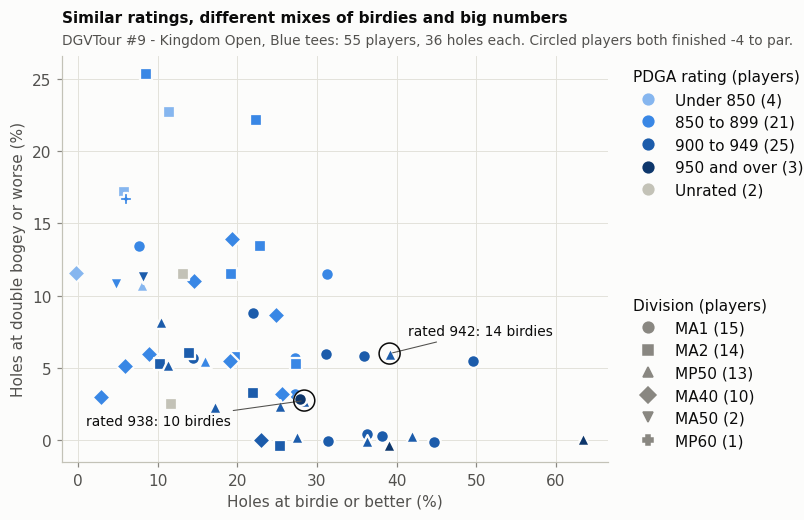

Saved to /Users/luc/Fall 2026/Data Science 2/disc-golf-play-styles-ds2-2026/Documents/figures: preliminary_figure.pdf and .png (proposal size), preliminary_figure_large.png
Circled players (event ratings): Todd Holmes, MP50, rated 938, 10 birdies; Chris Young, MP50, rated 942, 14 birdies


In [16]:
BANDS = ["Under 850", "850 to 899", "900 to 949", "950 and over"]
rates = full[full["layout"] == LAYOUT].copy()
rates["birdie_rate"] = 100 * rates["birdies"] / rates["holes"]
rates["double_rate"] = 100 * rates["doubles_plus"] / rates["holes"]
rates["band"] = (pd.cut(rates["rating"], bins=[0, 849, 899, 949, 2000], labels=BANDS)
                 .cat.add_categories("Unrated").fillna("Unrated"))
PLOT_BANDS = BANDS + ["Unrated"]
PLOT_COLORS = BAND_COLORS + ["#c3c2b7"]

# Rates move in steps of 1/36, so several players share the same point.
# A small fixed jitter keeps them all visible.
rng = np.random.default_rng(0)
rates["x"] = rates["birdie_rate"] + rng.uniform(-0.8, 0.8, len(rates))
rates["y"] = rates["double_rate"] + rng.uniform(-0.5, 0.5, len(rates))


# Division is shown by marker shape, largest division first.
DIVISIONS = rates["division"].value_counts().index.tolist()
DIV_MARKERS = dict(zip(DIVISIONS, ["o", "s", "^", "D", "v", "P", "X", "*"]))
assert len(DIV_MARKERS) == len(DIVISIONS)


def plot_preliminary(ax, compact=False):
    size = 34 if compact else 70
    ring = "white" if compact else SURFACE          # the proposal version sits on white paper
    for band, color in zip(PLOT_BANDS, PLOT_COLORS):
        for div, marker in DIV_MARKERS.items():
            d = rates[(rates["band"] == band) & (rates["division"] == div)]
            ax.scatter(d["x"], d["y"], s=size, color=color, marker=marker, edgecolor=ring,
                       linewidth=1.0 if compact else 1.5, zorder=3)

    # Circle the same-rating, same-score pair from section 6.
    if example["layout"] == LAYOUT:
        pair_pts = rates[rates["player_key"].isin(example_ids)].sort_values("birdies")
        offsets = [(-24, -13), (10, 10)] if compact else [(-48, -16), (12, 12)]
        for (_, r), off, ha in zip(pair_pts.iterrows(), offsets, ["right", "left"]):
            ax.scatter(r["x"], r["y"], s=size * 2.7, facecolor="none",
                       edgecolor=INK, linewidth=1.0, zorder=4)
            label = f"rated {int(r['rating'])}"
            if not compact:
                label += f": {int(r['birdies'])} birdies"
            ax.annotate(label, (r["x"], r["y"]), xytext=off, textcoords="offset points", ha=ha,
                        fontsize=7 if compact else 9, color=INK,
                        arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.7))

    ax.set_xlim(left=-2)
    ax.set_ylim(bottom=-1.5)
    ax.set_xlabel("Holes at birdie or better (%)")
    ax.set_ylabel("Holes at double bogey or worse (%)")
    # Two legends: color for rating band, shape for division.
    ms = 5 if compact else 7
    band_handles = [plt.Line2D([], [], linestyle="", marker="o", markersize=ms, color=color,
                               label=f"{band} ({int((rates['band'] == band).sum())})")
                    for band, color in zip(PLOT_BANDS, PLOT_COLORS)
                    if (rates["band"] == band).any()]
    div_handles = [plt.Line2D([], [], linestyle="", marker=marker, markersize=ms, color=MUTED,
                              label=f"{div} ({int((rates['division'] == div).sum())})")
                   for div, marker in DIV_MARKERS.items()]
    band_legend = ax.legend(handles=band_handles, title="PDGA rating (players)",
                            loc="upper left", bbox_to_anchor=(1.02, 1), alignment="left")
    ax.add_artist(band_legend)
    div_legend = ax.legend(handles=div_handles, title="Division (players)",
                           loc="lower left", bbox_to_anchor=(1.02, 0), alignment="left")
    return [band_legend, div_legend]


# Full-size version for the notebook.
fig, ax = plt.subplots(figsize=(6.4, 4.8))
legends = plot_preliminary(ax)
titled(ax, "Similar ratings, different mixes of birdies and big numbers",
       f"{info['name']}, {LAYOUT}: {len(rates)} players, 36 holes each. "
       f"Circled players both finished {int(example['to_par']):+d} to par.")
fig.savefig(FIG_DIR / "preliminary_figure_large.png", bbox_extra_artists=legends)
plt.show()

# Compact version sized for half a page width in the proposal (no title: the caption carries it).
with plt.rc_context({"font.size": 7.5, "axes.labelsize": 7.5, "xtick.labelsize": 7,
                     "ytick.labelsize": 7, "legend.fontsize": 7, "legend.title_fontsize": 7,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "savefig.facecolor": "white"}):
    fig, ax = plt.subplots(figsize=(2.6, 2.45))
    legends = plot_preliminary(ax, compact=True)
    fig.savefig(FIG_DIR / "preliminary_figure.pdf", bbox_extra_artists=legends)
    fig.savefig(FIG_DIR / "preliminary_figure.png", dpi=300, bbox_extra_artists=legends)
    plt.close(fig)
print(f"Saved to {FIG_DIR}: preliminary_figure.pdf and .png (proposal size), preliminary_figure_large.png")
pair_pts = rates[rates["player_key"].isin(example_ids)].sort_values("birdies")
print("Circled players (event ratings):",
      "; ".join(f"{names.loc[r.player_key, 'player_name']}, {r.division}, rated {int(r.rating)}, "
                f"{int(r.birdies)} birdies" for r in pair_pts.itertuples()))

The figure is saved to `Documents/figures/`, where the LaTeX proposal picks it up
(upload `figures/preliminary_figure.pdf` too if compiling on Overleaf):

```latex
\includegraphics[width=\linewidth]{preliminary_figure.pdf}
```

One event gives each player only 36 holes, so every point here is noisy: one extra
double bogey moves a player by 2.8 percentage points. The full tour data is what will
show whether these differences persist.

## 9. Short holes versus long holes

A first look at the kind of style the project is after. Each player's strokes gained per
hole is split between the nine shortest and nine longest holes of the layout. Distance
along the diagonal is overall skill. Distance *from* the diagonal is the interesting
part: players above it gain more on long holes, players below it gain more on short ones.

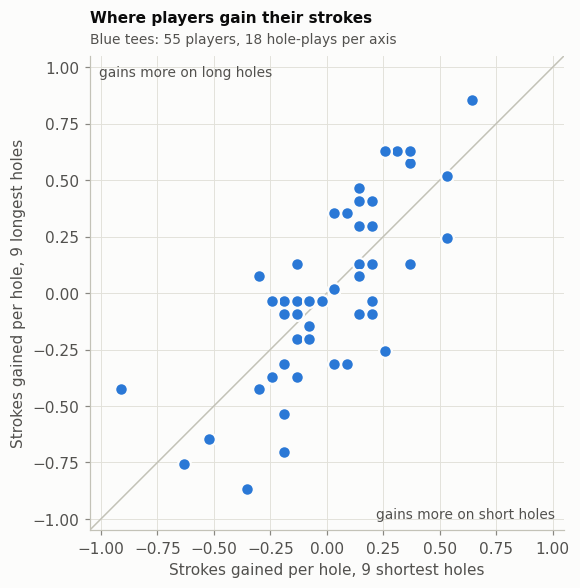

Correlation between short-hole and long-hole strokes gained: 0.76
Correlation between rating and (long minus short): 0.33


In [17]:
lay = holes[holes["layout"] == LAYOUT].copy()
lengths = lay.drop_duplicates("hole").set_index("hole")["length_ft"]
long_holes = lengths.sort_values().index[len(lengths) // 2:]
lay["hole_length"] = np.where(lay["hole"].isin(long_holes), "long", "short")

sg_split = (lay[lay["player_key"].isin(full["player_key"])]
            .pivot_table(index="player_key", columns="hole_length",
                         values="strokes_gained", aggfunc="mean"))
sg_split["rating"] = lay.groupby("player_key")["rating"].first()
sg_split["in_training"] = lay.groupby("player_key")["in_training"].all()
sg_split["long_minus_short"] = sg_split["long"] - sg_split["short"]

lim = float(np.ceil(sg_split[["long", "short"]].abs().max().max() * 10) / 10) + 0.05
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.plot([-lim, lim], [-lim, lim], color=AXIS, linewidth=1, zorder=1)
ax.scatter(sg_split["short"], sg_split["long"], s=70, color=BLUE,
           edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.text(-lim + 0.04, lim - 0.04, "gains more on long holes", ha="left", va="top",
        fontsize=9, color=INK_2)
ax.text(lim - 0.04, -lim + 0.04, "gains more on short holes", ha="right", va="bottom",
        fontsize=9, color=INK_2)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal")
ax.set_xlabel("Strokes gained per hole, 9 shortest holes")
ax.set_ylabel("Strokes gained per hole, 9 longest holes")
titled(ax, "Where players gain their strokes",
       f"{LAYOUT}: {len(sg_split)} players, 18 hole-plays per axis")
plt.show()

print(f"Correlation between short-hole and long-hole strokes gained: "
      f"{sg_split['short'].corr(sg_split['long']):.2f}")
print(f"Correlation between rating and (long minus short): "
      f"{sg_split.loc[sg_split['in_training'], 'rating'].corr(sg_split.loc[sg_split['in_training'], 'long_minus_short']):.2f} "
      f"(rated players only)")

With one event, each coordinate is an average of only 18 hole-plays, so the spread around
the diagonal is mostly noise. The test in the full project is whether a player's
position relative to the diagonal repeats from event to event.

One thing to carry forward: the second correlation printed above compares rating with
(long minus short). If it is clearly positive, higher-rated players gain relatively more on
long holes, which means a raw "long-hole player" label partly measures skill. The style
measure has to be adjusted for rating before clustering.

## 10. Every number the proposal quotes, in one table

Each value below is computed from the data above. If a later scrape changes the data,
rerun the notebook and compare this table with the proposal text.

In [18]:
gold = layouts.index[0]                                   # the longest layout
gold_lengths = length_by_par[length_by_par["layout"] == gold].set_index("par")
shares = mix_table["share (%)"].round(0).astype(int)
lo, hi = example_rows.iloc[0], example_rows.iloc[1]

proposal_numbers = pd.DataFrame([
    ("Example event", "Players", n_players),
    ("Example event", "Players unrated at the time of the event", n_unrated),
    ("Example event", "Divisions with players", n_divisions),
    ("Example event", "Rounds", n_rounds),
    ("Example event", "Player-hole scores", f"{n_player_holes:,}"),
    ("Example event", "Completed player-rounds whose holes sum to the round score",
     f"{n_sum_ok} of {n_completed}"),
    ("Hole type", f"Par 3 length range on the longest layout ({gold})",
     f"{int(gold_lengths.loc[3, 'shortest_ft'])} to {int(gold_lengths.loc[3, 'longest_ft'])} ft"),
    ("Hole type", f"Par 4 length range on the longest layout ({gold})",
     f"{int(gold_lengths.loc[4, 'shortest_ft'])} to {int(gold_lengths.loc[4, 'longest_ft'])} ft"),
    ("Cleaning risks", "Layouts",
     "; ".join(f"{name}: {int(r.length_ft):,} ft, par {int(r.par)}, {int(r.players)} players"
               for name, r in layouts.iterrows())),
    ("Cleaning risks", "Divisions with three or fewer players",
     f"{n_small_divs} of {len(div_sizes)}"),
    ("Cleaning risks", "Unfinished rounds stored as 999 and flagged completed", len(dnf)),
    ("Cleaning risks", "Hole-score rows missing a length",
     f"{n_len_missing:,} of {len(hole_scores):,}"),
    ("Cleaning risks", "Tee times", f"{first_tee[:5]} to {last_tee[:5]}"),
    ("Cleaning risks", f"Two par 4s of nearly the same length ({LAYOUT})",
     f"{int(closest['length_gap'])} ft apart in length, "
     f"{closest['score_gap']:.2f} strokes apart in average score"),
    ("Predictive", "Score mix: birdie+, par, bogey, double+",
     ", ".join(f"{v}%" for v in shares)),
    ("Figure 1", "Players on the figure's layout with 36 holes", f"{len(rates)} ({LAYOUT})"),
    ("Figure 1", "Circled same-score pair",
     f"{lo['division']}, rated {int(lo['rating'])} and {int(hi['rating'])}, both "
     f"{int(lo['to_par']):+d} over 36 holes: {int(lo['birdies'])} birdies and "
     f"{int(lo['over_par_holes'])} holes over par vs {int(hi['birdies'])} birdies and "
     f"{int(hi['over_par_holes'])} holes over par"),
], columns=["proposal section", "claim", "value from the data"])

with pd.option_context("display.max_colwidth", None):
    display(proposal_numbers)

,proposal section,claim,value from the data
0,Example event,Players,104
1,Example event,Players unrated at the time of the event,7
2,Example event,Divisions with players,17
3,Example event,Rounds,2
4,Example event,Player-hole scores,"3,708"
5,Example event,Completed player-rounds whose holes sum to the round score,206 of 206
6,Hole type,Par 3 length range on the longest layout (Gold tees),240 to 492 ft
7,Hole type,Par 4 length range on the longest layout (Gold tees),414 to 631 ft
8,Cleaning risks,Layouts,"Gold tees: 8,001 ft, par 64, 24 players; Blue tees: 7,054 ft, par 65, 56 players; White tees: 5,153 ft, par 63, 19 players; Red tees: 4,034 ft, par 63, 5 players"
9,Cleaning risks,Divisions with three or fewer players,10 of 17
